# JAO Feature Selection

The previous notebook saved the second-ring series as raw columns: eight zones in each of `pca_np`, `pca_gen` and `pca_load`. This notebook fits one PCA per group on the training window and keeps the smallest number of components that explains at least 90% of the variance.

PCA is not standardized. Columns inside a group share a unit, and a zone with a wider range, such as FR against SI, should weigh more on the components.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent.parent.parent))

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from src.config import (
    TRAIN_DATASET_START,
    TRAIN_DATASET_END,
    DATA_DIR,
    DOWNLOAD_START_DATE,
    DOWNLOAD_END_DATE,
)
from src.utils.feature_engineering.fe_jao import PCA_GROUPS, select_pca_group
from src.utils.file_io import load_merged_data

In [2]:
date_range = f"{DOWNLOAD_START_DATE}_{DOWNLOAD_END_DATE}"
data_jao = load_merged_data(
    DATA_DIR / "features" / "jao" / "trees" / "pl_foreign" / f"{date_range}.parquet"
)

## 1. Groups

`select_pca_group` returns one block from `PCA_GROUPS`. The source is the trees file `pl_foreign`, cut to `TRAIN_DATASET_START`–`TRAIN_DATASET_END`.

In [3]:
data_pca = data_jao.loc[TRAIN_DATASET_START:TRAIN_DATASET_END].copy()

for group in PCA_GROUPS:
    df = select_pca_group(data_pca, group)
    print(list(df.columns))
    print(group, df.shape[1])

['pca_np_AT', 'pca_np_BE', 'pca_np_FR', 'pca_np_HR', 'pca_np_HU', 'pca_np_NL', 'pca_np_RO', 'pca_np_SI']
pca_np 8
['pca_gen_AT', 'pca_gen_BE', 'pca_gen_FR', 'pca_gen_HR', 'pca_gen_HU', 'pca_gen_NL', 'pca_gen_RO', 'pca_gen_SI']
pca_gen 8
['pca_load_AT', 'pca_load_BE', 'pca_load_FR', 'pca_load_HR', 'pca_load_HU', 'pca_load_NL', 'pca_load_RO', 'pca_load_SI']
pca_load 8


## 2. Share of Variance

Eight components is the full rank of each block. The table is the share explained by PC1 through PC8.

In [4]:
pca = {
    group: PCA(n_components=8)
    .fit(select_pca_group(data_pca, group))
    .explained_variance_ratio_
    for group in PCA_GROUPS
}

In [5]:
df = pd.DataFrame({group: pca[group] for group in PCA_GROUPS})
df["PC"] = range(1, 9)
df.set_index("PC", inplace=True)
df

,pca_np,pca_gen,pca_load
PC,,,
1,0.647843,0.837410,0.881591
2,0.115942,0.092150,0.082762
3,0.084909,0.030351,0.015673
4,0.059480,0.021960,0.008848
5,0.045455,0.008725,0.006269
6,0.024039,0.008216,0.002620
7,0.014216,0.000671,0.001443
8,0.008116,0.000517,0.000794


## 3. Cumulative Share

Running sum of the shares from section 2. 90% is the cutoff used below.

In [6]:
for col in df.columns:
    display(np.cumsum(df[col], axis=0))

PC
1    0.647843
2    0.763785
3    0.848694
4    0.908175
5    0.953629
6    0.977668
7    0.991884
8    1.000000
Name: pca_np, dtype: float64

PC
1    0.837410
2    0.929560
3    0.959912
4    0.981871
5    0.990596
6    0.998812
7    0.999483
8    1.000000
Name: pca_gen, dtype: float64

PC
1    0.881591
2    0.964353
3    0.980026
4    0.988873
5    0.995143
6    0.997763
7    0.999206
8    1.000000
Name: pca_load, dtype: float64

## 4. Plot

The shares from section 2, one panel per group, on a common scale.

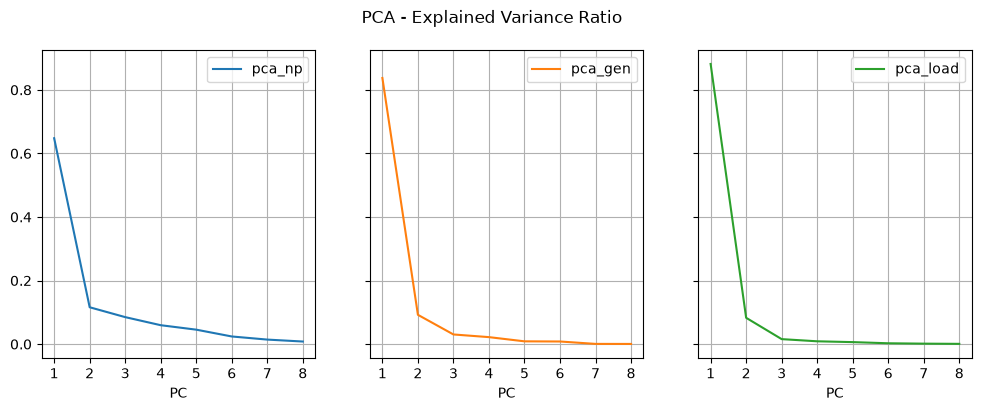

In [7]:
df.plot(
    subplots=True,
    layout=(1, 3),
    sharey=True,
    sharex=True,
    figsize=(12, 4),
    grid=True,
    xticks=[1, 2, 3, 4, 5, 6, 7, 8],
)
plt.suptitle("PCA - Explained Variance Ratio")
plt.show()

## 5. Conclusions

* `pca_np` — PC1 is 64.8% and the rest falls off slowly, with no elbow. Four components reach 90.8%.
* `pca_gen` — PC1 is 83.7% and PC2 is 9.2%. Two components reach 93.0%. From PC3 each share is at most 3.0%.
* `pca_load` — PC1 is 88.2% and PC2 is 8.3%. Two components reach 96.4%. From PC3 each share is under 1.6%.

The same 90% rule applies to every group: 4, 2 and 2 components. The 24 second-ring columns become 8.